100%|██████████| 4.85M/4.85M [00:00<00:00, 52.6MB/s]

Extracting files...


Dataset loaded: (374661, 19)

Accuracy: 99.76245445931698 %

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     68014
    Abnormal       0.99      0.99      0.99      6919

    accuracy                           1.00     74933
   macro avg       0.99      0.99      0.99     74933
weighted avg       1.00      1.00      1.00     74933


Event Classification:
Normal: 68028
Abnormal: 6905


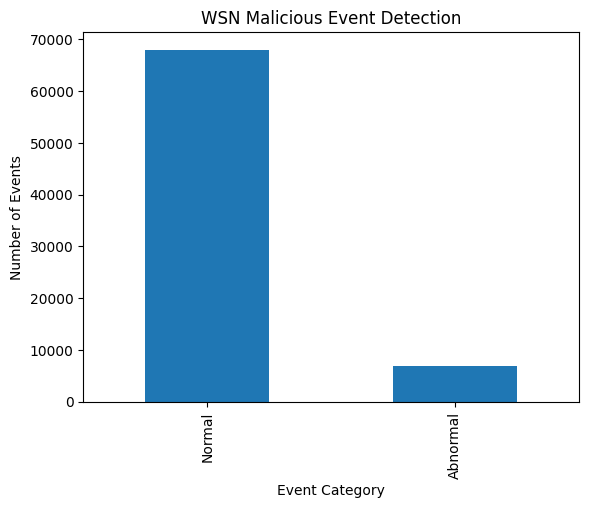

In [ ]:

# Install and import libraries
!pip -q install kagglehub

import kagglehub
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load WSN-DS dataset
path = kagglehub.dataset_download("bassamkasasbeh1/wsnds")

file = next(os.path.join(r, f) for r, d, fs in os.walk(path)
            for f in fs if f.endswith(".csv"))

df = pd.read_csv(file)
df.columns = df.columns.str.strip().str.replace(" ", "_")

print("Dataset loaded:", df.shape)

# Prepare features and labels
target = next(c for c in df.columns if c.lower() == "attack_type")

df[target] = df[target].astype(str).str.strip().str.lower()
y = df[target].apply(lambda x: 0 if x in ["normal", "normal."] else 1)

X = df.drop(columns=[target]).select_dtypes(include="number")

# Train and test model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict and evaluate
predictions = model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, predictions) * 100, "%")
print("\nClassification Report:")
print(classification_report(y_test, predictions,
                            target_names=["Normal", "Abnormal"]))

# Display classification results
print("\nEvent Classification:")
print("Normal:", sum(predictions == 0))
print("Abnormal:", sum(predictions == 1))

# Visualise results
pd.Series(predictions).map(
    {0: "Normal", 1: "Abnormal"}
).value_counts().plot(kind="bar")

plt.title("WSN Malicious Event Detection")
plt.xlabel("Event Category")
plt.ylabel("Number of Events")
plt.show()
